# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Ghibli AI Art Images Dataset](https://www.kaggle.com/datasets/abacilla/ghibli-style-ai-art-images-created-per-hour)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

/kaggle/input/datasets/abacilla/ghibli-style-ai-art-images-created-per-hour/ghibli_ai_art_images_per_hour_dataset.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('ghibli_ai_art_images_per_hour_dataset.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,trend_search_volume,active_ai_tool_users,hours_since_trend_started,social_media_mentions_count,platform,art_style_variant,is_peak_hour,featured_by_influencer,images_created_per_hour
0,1388.79,1098.0,56.56,671,TikTok,Classic Ghibli,0.0,0,24
1,196.00,1233.0,8.94,910,Instagram,Modern Fusion,1.0,0,107
2,178.43,767.0,11.93,353,X/Twitter,Classic Ghibli,0.0,0,114
3,495.56,429.0,19.16,899,Reddit,Classic Ghibli,1.0,1,153
4,114.98,1349.0,185.31,1392,Instagram,Classic Ghibli,1.0,0,67


## last Five row

In [4]:
df.tail()

,trend_search_volume,active_ai_tool_users,hours_since_trend_started,social_media_mentions_count,platform,art_style_variant,is_peak_hour,featured_by_influencer,images_created_per_hour
26995,800.21,365.0,51.93,503,Reddit,Classic Ghibli,0.0,0,60
26996,116.57,2612.0,24.99,298,X/Twitter,Classic Ghibli,1.0,0,133
26997,32.67,644.0,5.69,151,Reddit,Modern Fusion,0.0,0,31
26998,40.10,1440.0,33.54,776,X/Twitter,Character Focus,1.0,1,127
26999,134.93,1535.0,36.32,1890,Instagram,Classic Ghibli,1.0,0,112


## Shape of our dataset

In [5]:
df.shape

(27000, 9)

## List out all columns

In [6]:
df.columns

Index(['trend_search_volume', 'active_ai_tool_users',
       'hours_since_trend_started', 'social_media_mentions_count', 'platform',
       'art_style_variant', 'is_peak_hour', 'featured_by_influencer',
       'images_created_per_hour'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

trend_search_volume            float64
active_ai_tool_users           float64
hours_since_trend_started      float64
social_media_mentions_count      int64
platform                        object
art_style_variant               object
is_peak_hour                   float64
featured_by_influencer           int64
images_created_per_hour          int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27000 entries, 0 to 26999
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   trend_search_volume          27000 non-null  float64
 1   active_ai_tool_users         25652 non-null  float64
 2   hours_since_trend_started    27000 non-null  float64
 3   social_media_mentions_count  27000 non-null  int64  
 4   platform                     27000 non-null  object 
 5   art_style_variant            27000 non-null  object 
 6   is_peak_hour                 26195 non-null  float64
 7   featured_by_influencer       27000 non-null  int64  
 8   images_created_per_hour      27000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.9+ MB


## Check Null Value

In [9]:
df.isnull().sum()

trend_search_volume               0
active_ai_tool_users           1348
hours_since_trend_started         0
social_media_mentions_count       0
platform                          0
art_style_variant                 0
is_peak_hour                    805
featured_by_influencer            0
images_created_per_hour           0
dtype: int64

## Handle missing numerical values

In [10]:
df['active_ai_tool_users'] = df['active_ai_tool_users'].fillna(df['active_ai_tool_users'].median())
df['is_peak_hour'] = df['is_peak_hour'].fillna(df['is_peak_hour'].mode()[0])

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(5000)

## Drop Duplicates

In [12]:
df.drop_duplicates(inplace=True)

## Summary

In [13]:
df.describe()

,trend_search_volume,active_ai_tool_users,hours_since_trend_started,social_media_mentions_count,is_peak_hour,featured_by_influencer,images_created_per_hour
count,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000
mean,564.450981,1194.348818,33.312577,604.724591,0.291545,0.116364,98.012955
std,688.956470,676.232389,36.664426,430.476711,0.454484,0.320668,51.436904
min,30.000000,50.000000,1.000000,5.000000,0.000000,0.000000,0.000000
25%,105.220000,710.000000,8.117500,290.000000,0.000000,0.000000,62.000000
50%,309.755000,1077.000000,21.260000,507.000000,0.000000,0.000000,94.000000
75%,757.595000,1527.000000,45.182500,810.000000,1.000000,0.000000,129.000000
max,9182.290000,5699.000000,447.300000,3763.000000,1.000000,1.000000,382.000000


# EDA

In [14]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

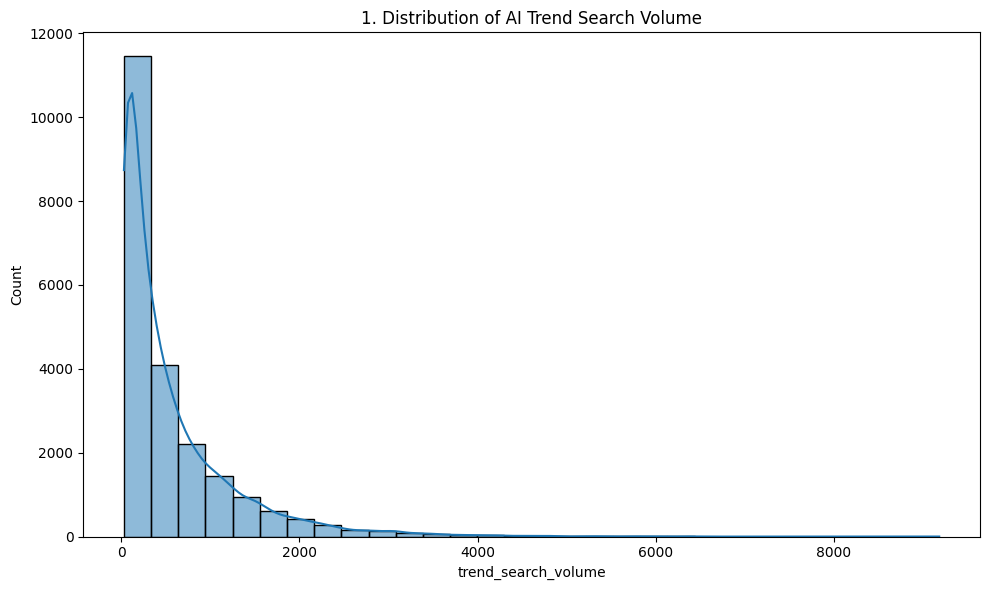

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='trend_search_volume', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of AI Trend Search Volume')
show_fig()
plot_no += 1

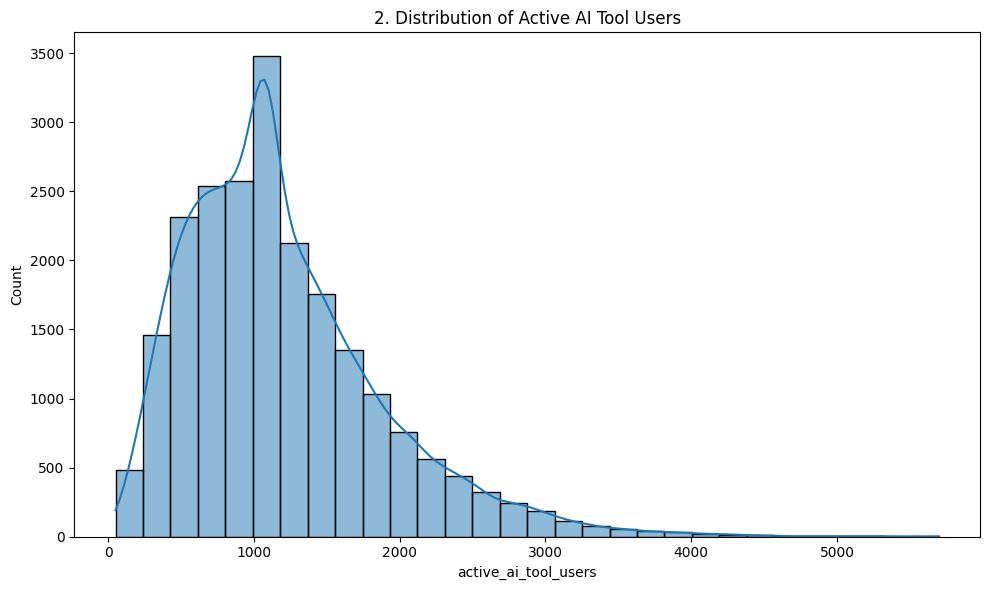

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='active_ai_tool_users', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Active AI Tool Users')
show_fig()
plot_no += 1

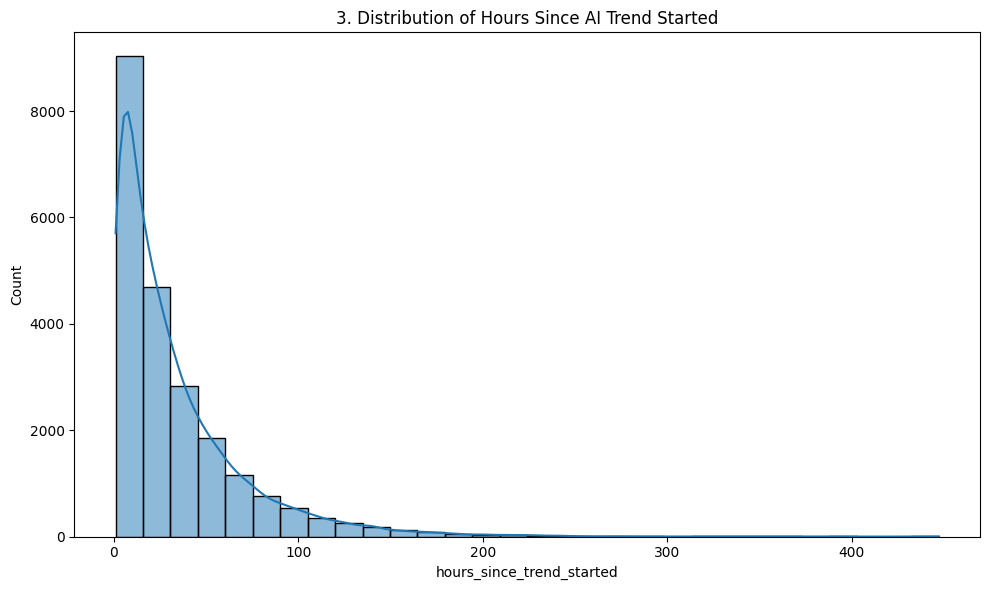

In [17]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='hours_since_trend_started', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Hours Since AI Trend Started')
show_fig()
plot_no += 1

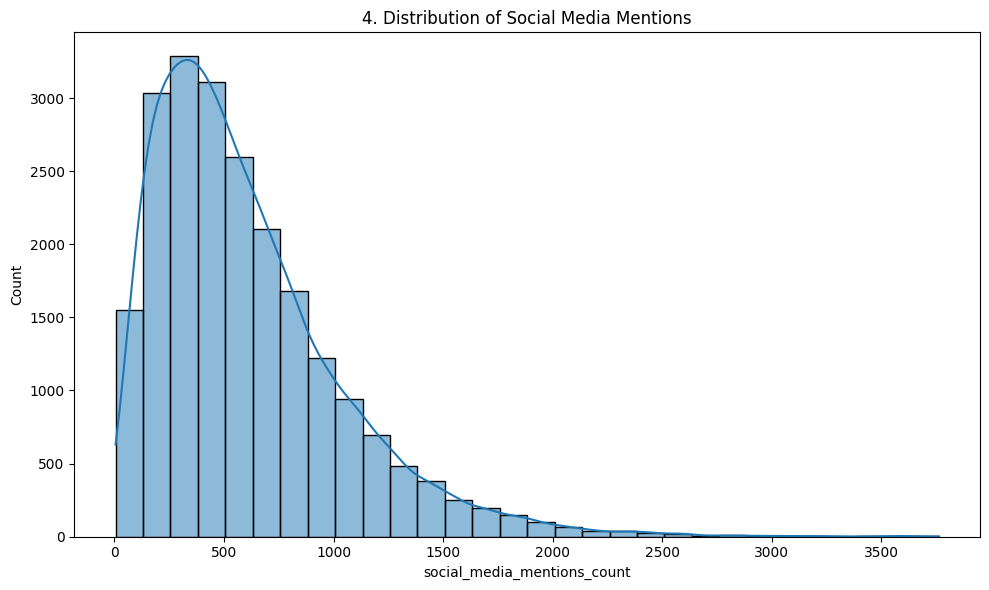

In [18]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='social_media_mentions_count', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Social Media Mentions')
show_fig()
plot_no += 1

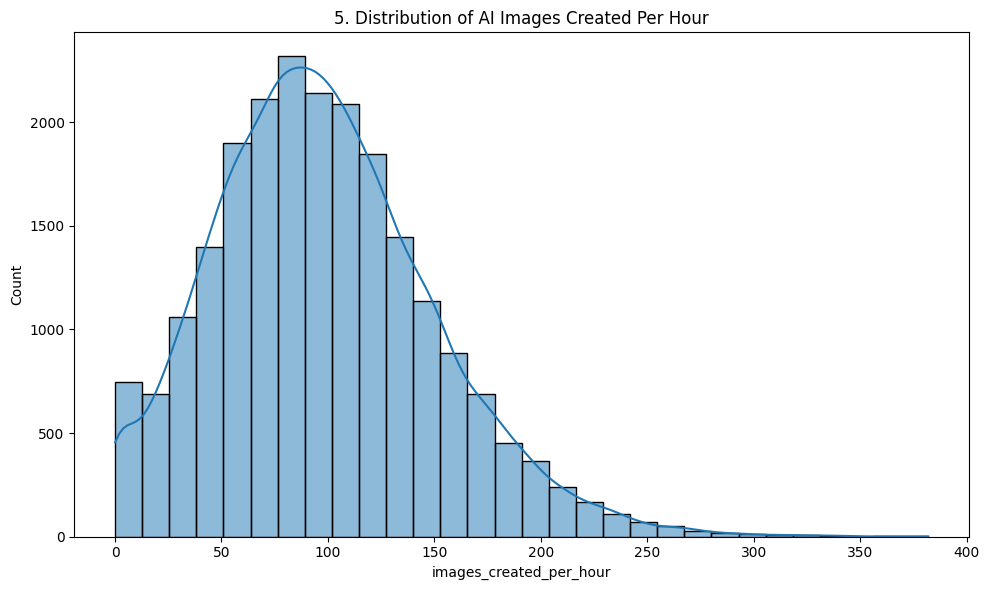

In [19]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='images_created_per_hour', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of AI Images Created Per Hour')
show_fig()
plot_no += 1

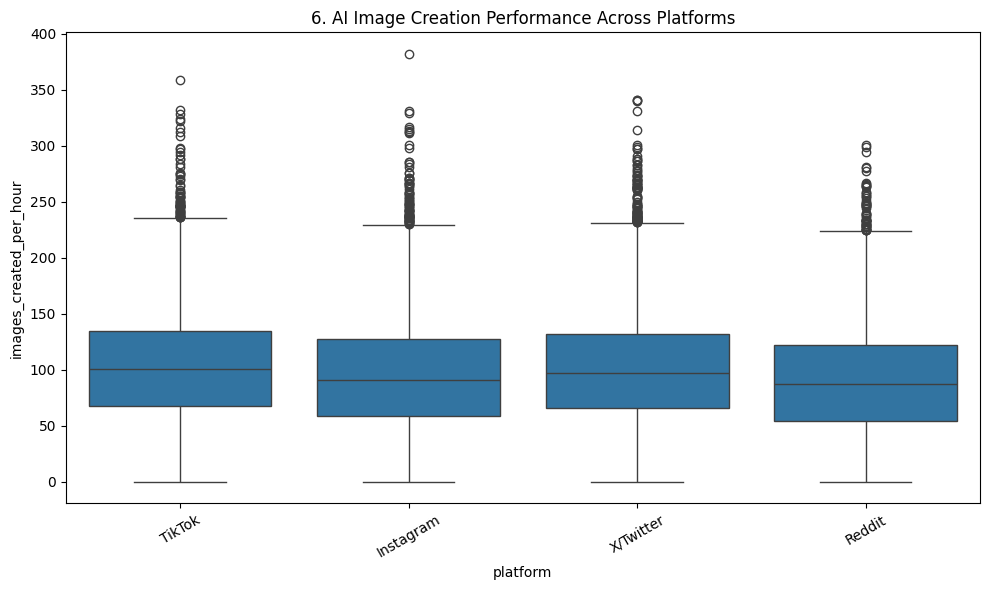

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='platform', y='images_created_per_hour')
plt.title(f'{plot_no}. AI Image Creation Performance Across Platforms')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

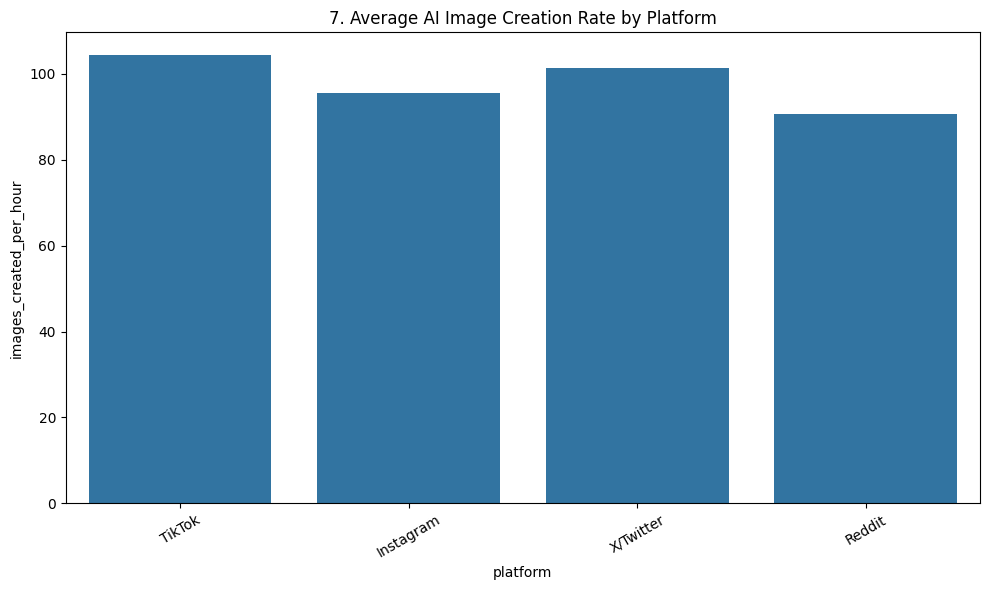

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='platform', y='images_created_per_hour', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average AI Image Creation Rate by Platform')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

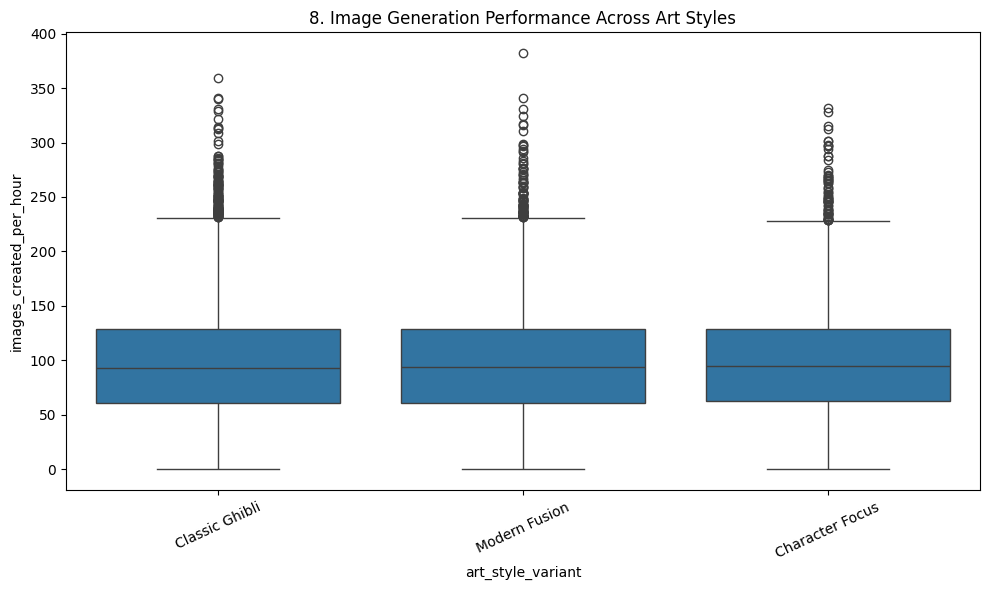

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='art_style_variant', y='images_created_per_hour')
plt.title(f'{plot_no}. Image Generation Performance Across Art Styles')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

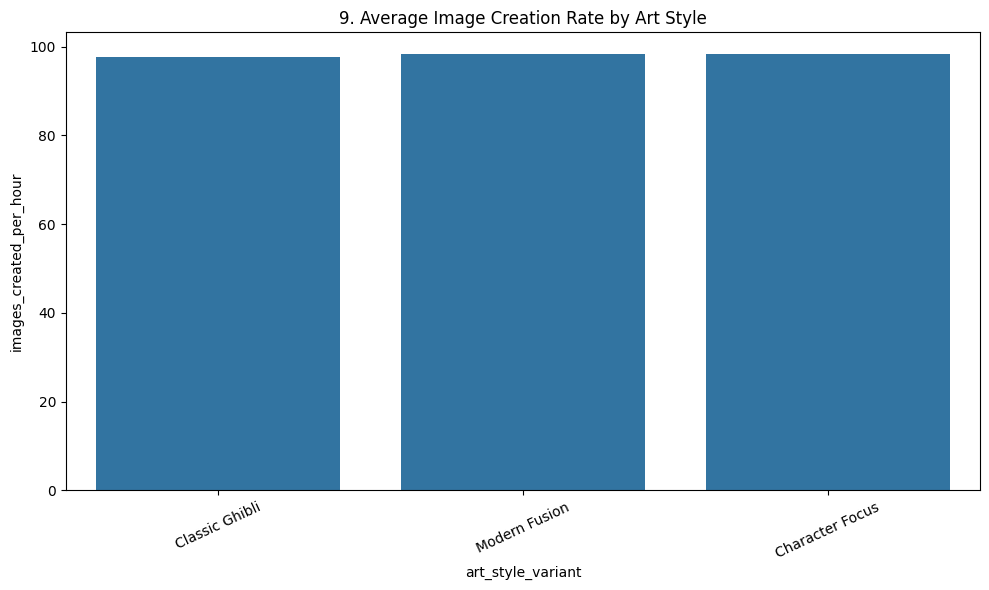

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='art_style_variant', y='images_created_per_hour', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Image Creation Rate by Art Style')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

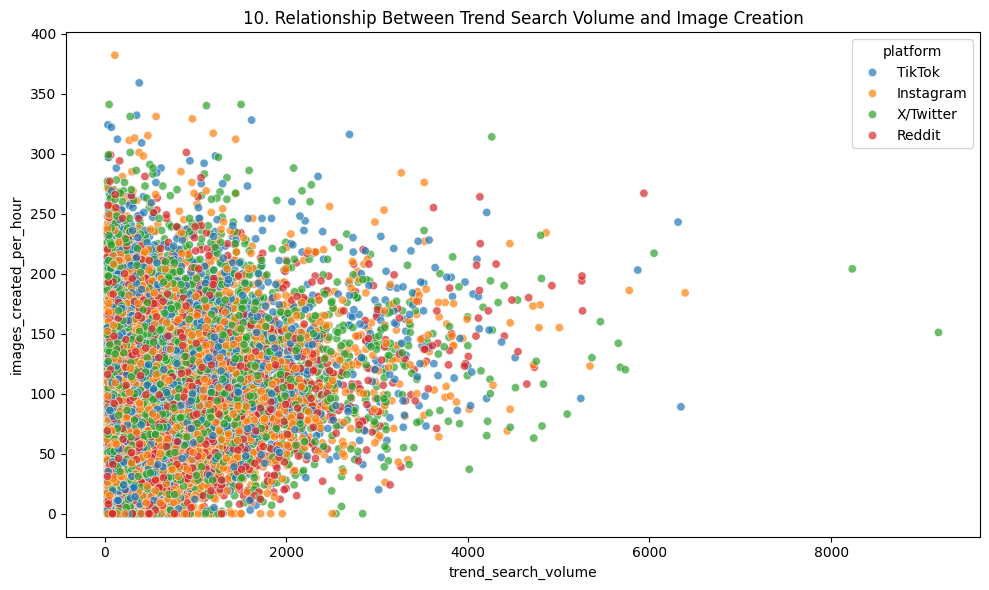

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='trend_search_volume', y='images_created_per_hour', hue='platform', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Trend Search Volume and Image Creation')
show_fig()
plot_no += 1

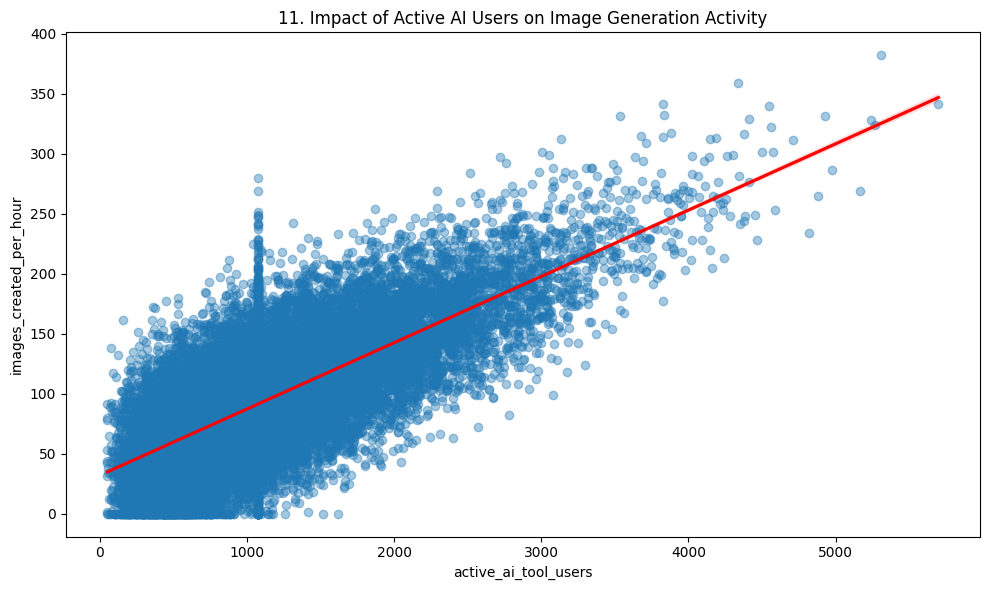

In [25]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='active_ai_tool_users', y='images_created_per_hour', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Impact of Active AI Users on Image Generation Activity')
show_fig()
plot_no += 1

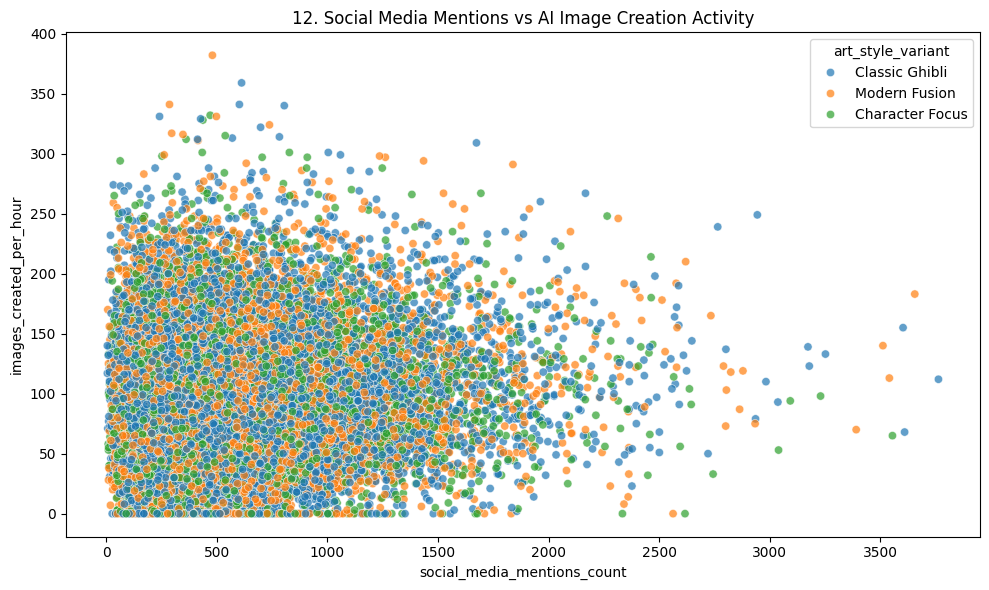

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_media_mentions_count', y='images_created_per_hour', hue='art_style_variant', alpha=0.7)
plt.title(f'{plot_no}. Social Media Mentions vs AI Image Creation Activity')
show_fig()
plot_no += 1

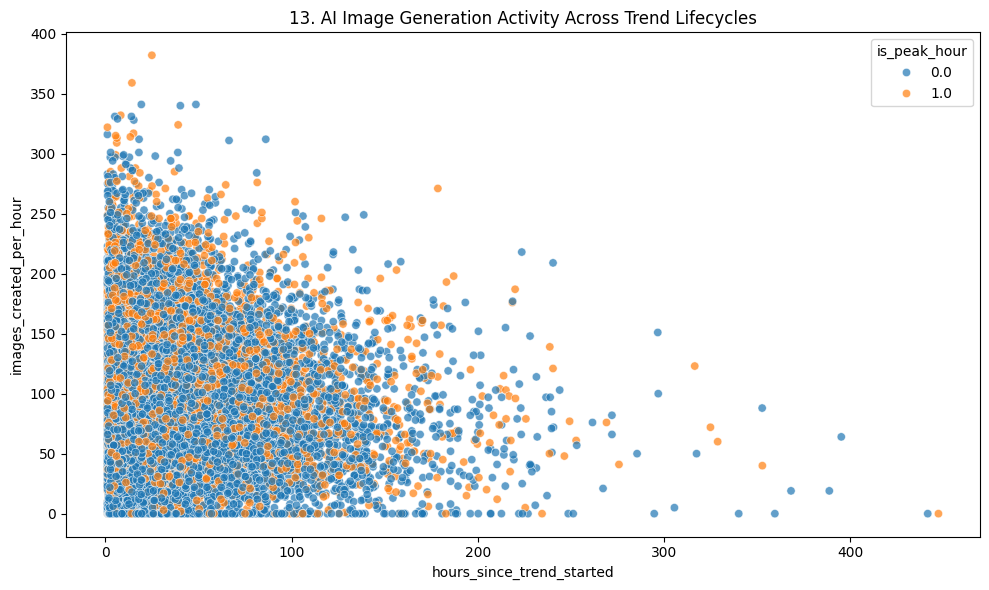

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='hours_since_trend_started', y='images_created_per_hour', hue='is_peak_hour', alpha=0.7)
plt.title(f'{plot_no}. AI Image Generation Activity Across Trend Lifecycles')
show_fig()
plot_no += 1

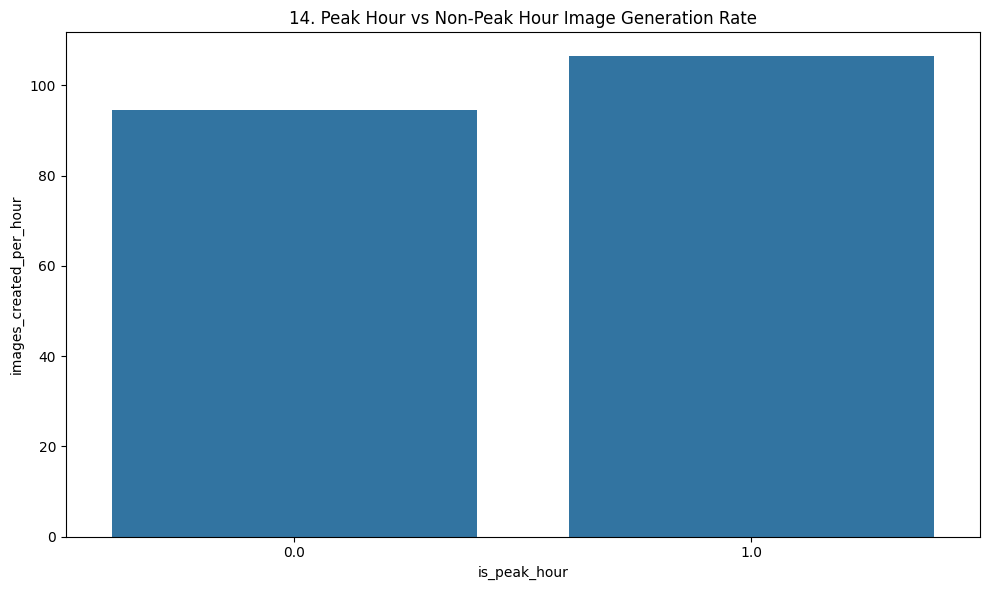

In [28]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='is_peak_hour', y='images_created_per_hour', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Peak Hour vs Non-Peak Hour Image Generation Rate')
show_fig()
plot_no += 1

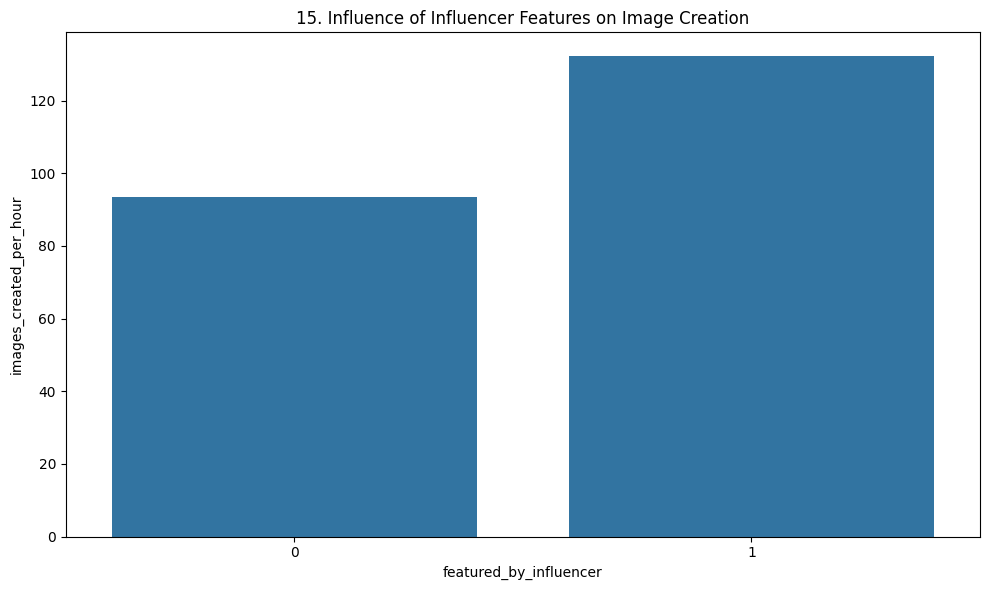

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='featured_by_influencer', y='images_created_per_hour', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Influence of Influencer Features on Image Creation')
show_fig()
plot_no += 1

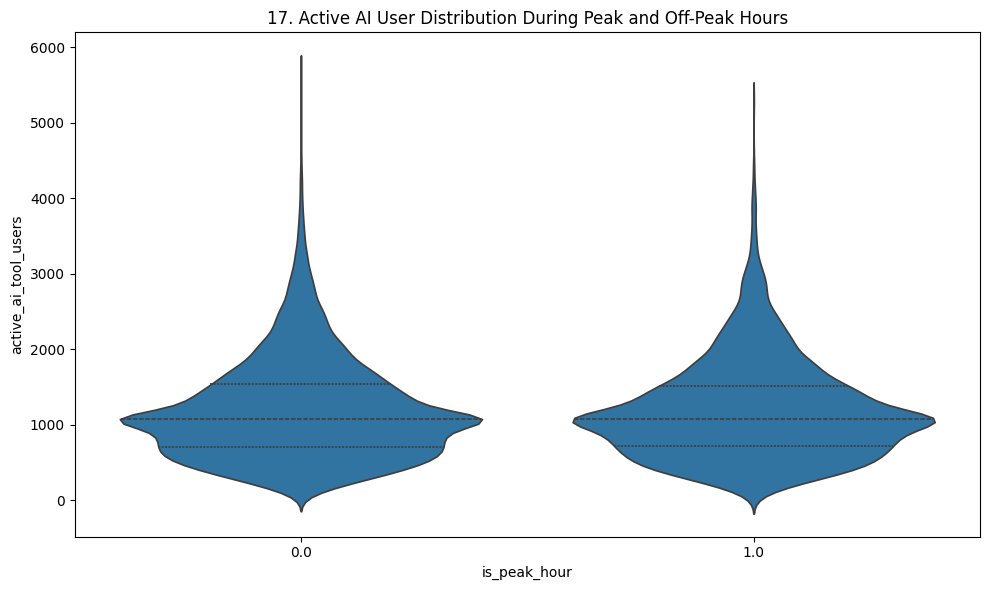

In [31]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='is_peak_hour', y='active_ai_tool_users', inner='quartile')
plt.title(f'{plot_no}. Active AI User Distribution During Peak and Off-Peak Hours')
show_fig()
plot_no += 1

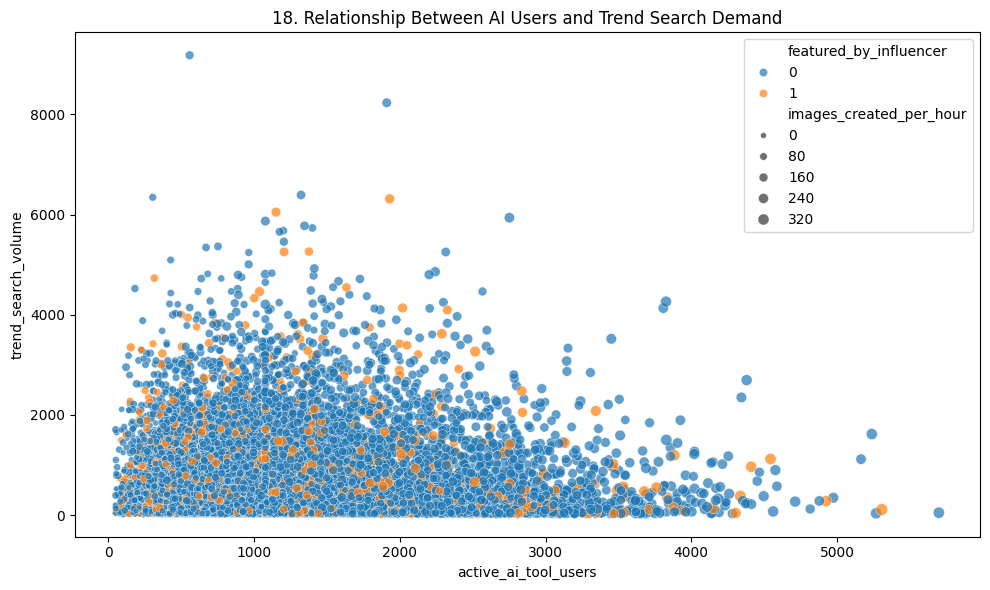

In [32]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='active_ai_tool_users', y='trend_search_volume', hue='featured_by_influencer', size='images_created_per_hour', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between AI Users and Trend Search Demand')
show_fig()
plot_no += 1

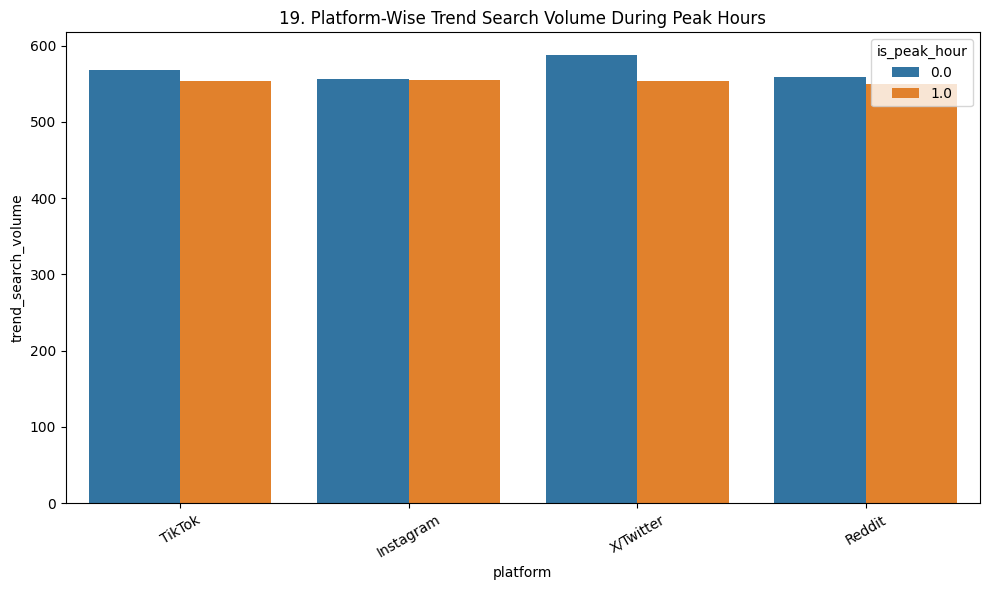

In [33]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='platform', y='trend_search_volume', hue='is_peak_hour', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Platform-Wise Trend Search Volume During Peak Hours')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

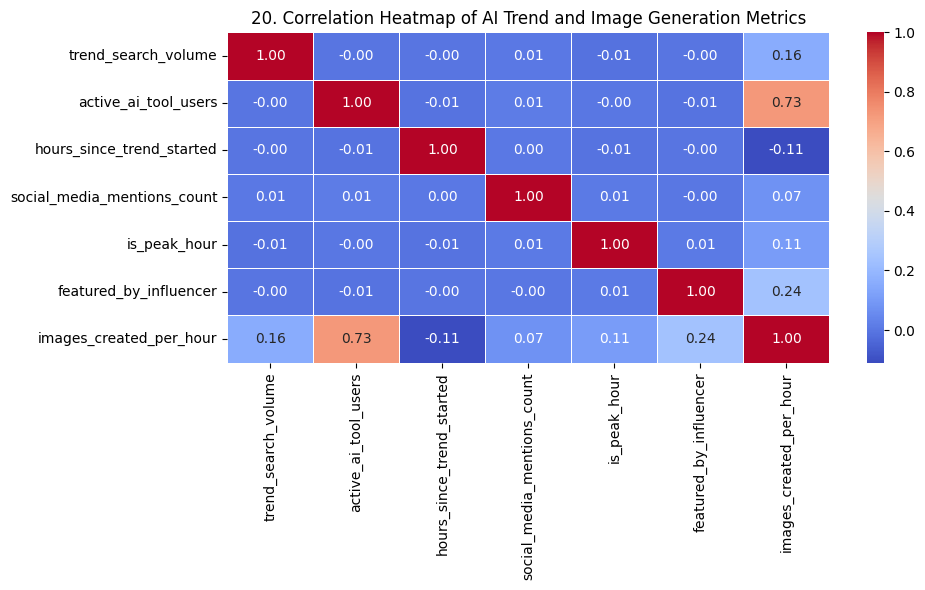

In [34]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of AI Trend and Image Generation Metrics')
show_fig()
plot_no += 1

In [35]:
corr

,trend_search_volume,active_ai_tool_users,hours_since_trend_started,social_media_mentions_count,is_peak_hour,featured_by_influencer,images_created_per_hour
trend_search_volume,1.000000,-0.001630,-0.003650,0.005423,-0.010463,-0.002078,0.157604
active_ai_tool_users,-0.001630,1.000000,-0.007332,0.013350,-0.000239,-0.006944,0.726055
hours_since_trend_started,-0.003650,-0.007332,1.000000,0.003496,-0.006484,-0.001623,-0.109551
social_media_mentions_count,0.005423,0.013350,0.003496,1.000000,0.008590,-0.000729,0.074675
is_peak_hour,-0.010463,-0.000239,-0.006484,0.008590,1.000000,0.008622,0.105101
featured_by_influencer,-0.002078,-0.006944,-0.001623,-0.000729,0.008622,1.000000,0.240903
images_created_per_hour,0.157604,0.726055,-0.109551,0.074675,0.105101,0.240903,1.000000


# Model Training

## Separate features and target

In [36]:
X = df.drop(columns=['images_created_per_hour'])
y = df['images_created_per_hour']

## Identify numerical and categorical columns

In [37]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Create preprocessing pipeline

In [38]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Combine preprocessing

In [39]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Split dataset

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create model

In [41]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=2,
        random_state=42
    ))
])

## Train model

In [42]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['trend_search_volume', 'active_ai_tool_users',
       'hours_since_trend_started', 'social_media_mentions_count',
       'is_peak_hour', 'featured_by_influencer'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['platform', 'art_style_variant'], dtype='object'))])),
                ('regressor',
                 HistGradientBoostingRegressor(l2_regularization=2,
                                               learning_rate=0.05, max_iter=300,
                                               max_leaf_nodes=20,
                                               random_state=42))])

## Make predictions

In [43]:
y_pred = model.predict(X_test)

## Evaluate model

In [44]:
print("R2 Score:", round(r2_score(y_test, y_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("Accuracy-like R2 Percentage:", round(r2_score(y_test, y_pred) * 100, 2), "%")

R2 Score: 0.6241
MAE: 24.7593
RMSE: 31.3441
Accuracy-like R2 Percentage: 62.41 %


## Plot actual vs predicted values

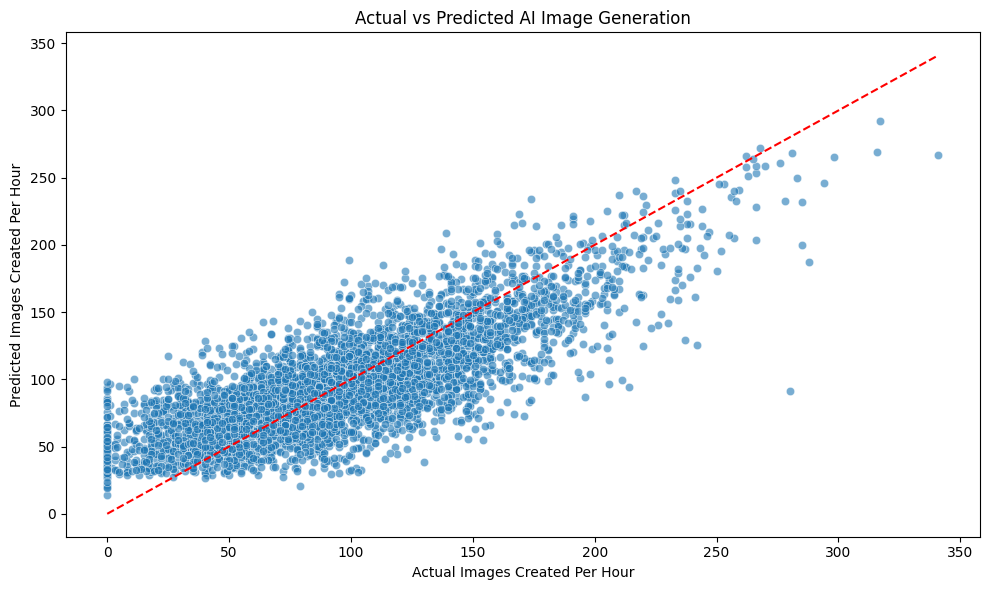

In [45]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Images Created Per Hour')
plt.ylabel('Predicted Images Created Per Hour')
plt.title('Actual vs Predicted AI Image Generation')
show_fig()